# Stock price forecasting using LOB

Before start, we need to test some libraries in order to build a reasonable dataset for the neural network architecture. Test will be focused on libraries for crypto market data and stock market data. For more corporate indices (bank indices) maybe there are other libraries to test in a second moment.

### Import modules

In [1]:
import time 
import pandas
import random
import json, argparse

# ML
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from plotly.subplots import make_subplots
from plotly import graph_objects as go
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, roc_auc_score, mean_absolute_percentage_error, root_mean_squared_error

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import models_regression as Models
import utils
import dataset as Dataset

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

Using device: cuda:0


## Multi Horizon Regression:

In [3]:
dataset = pd.read_parquet('/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/Data/LOBSTER/MSFT.parquet')
dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
dataset = dataset.astype(float)
dataset = dataset.head(200000)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,309900.0,3788.0,309500.0,300.0,310500.0,100.0,309300.0,3986.0,310600.0,100.0,...,400.0,311300.0,100.0,308500.0,400.0,311400.0,100.0,308400.0,1600.0,309700.0
1,309900.0,3788.0,309500.0,300.0,310500.0,200.0,309300.0,3986.0,310600.0,100.0,...,400.0,311300.0,100.0,308500.0,400.0,311400.0,100.0,308400.0,1600.0,309700.0
2,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,200.0,...,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309700.0
3,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309700.0
4,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309700.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,308300.0,26720.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308200.0
199996,308300.0,28220.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308200.0
199997,308300.0,26720.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308200.0
199998,308300.0,25520.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308200.0


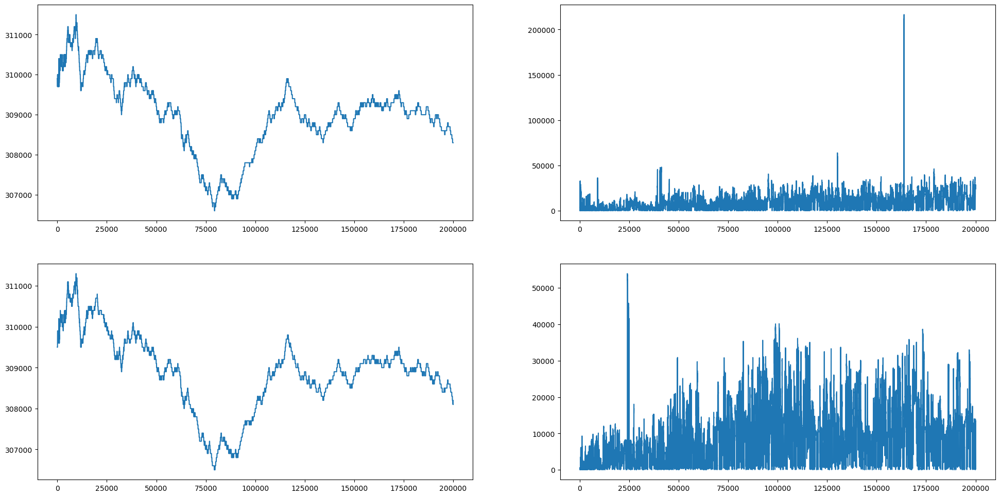

In [4]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(dataset['P_Ask_1'])
axs[0,1].plot(dataset['V_Ask_1'])
axs[1,0].plot(dataset['P_Bid_1'])
axs[1,1].plot(dataset['V_Bid_1'])
plt.show()

In [5]:
target_col = 'mid_price'
target_cols = []
shifts = [ 10, 20, 30, 50 ]

for shift in shifts:
    colname = f'Target_{shift}'
    target_cols.append(colname)
    dataset[colname] = dataset[target_col].shift(-shift)
dataset.dropna(inplace=True)

display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_10,Target_20,Target_30,Target_50
0,309900.0,3788.0,309500.0,300.0,310500.0,100.0,309300.0,3986.0,310600.0,100.0,...,400.0,311400.0,100.0,308400.0,1600.0,309700.0,309700.0,309700.0,309700.0,309600.0
1,309900.0,3788.0,309500.0,300.0,310500.0,200.0,309300.0,3986.0,310600.0,100.0,...,400.0,311400.0,100.0,308400.0,1600.0,309700.0,309700.0,309700.0,309700.0,309600.0
2,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,200.0,...,400.0,311300.0,100.0,308400.0,1600.0,309700.0,309700.0,309700.0,309700.0,309600.0
3,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,400.0,311300.0,100.0,308400.0,1600.0,309700.0,309700.0,309700.0,309700.0,309600.0
4,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,400.0,311300.0,100.0,308400.0,1600.0,309700.0,309700.0,309700.0,309700.0,309600.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199945,308300.0,26220.0,308200.0,600.0,308400.0,24832.0,308100.0,13361.0,308500.0,15631.0,...,3200.0,309200.0,7700.0,307300.0,1900.0,308250.0,308250.0,308200.0,308200.0,308200.0
199946,308300.0,26220.0,308200.0,200.0,308400.0,24832.0,308100.0,13361.0,308500.0,15631.0,...,3200.0,309200.0,7700.0,307300.0,1900.0,308250.0,308250.0,308200.0,308200.0,308200.0
199947,308300.0,25520.0,308200.0,200.0,308400.0,24832.0,308100.0,13361.0,308500.0,15631.0,...,3200.0,309200.0,7700.0,307300.0,1900.0,308250.0,308250.0,308200.0,308200.0,308200.0
199948,308300.0,25520.0,308200.0,1400.0,308400.0,24832.0,308100.0,13361.0,308500.0,15631.0,...,3200.0,309200.0,7700.0,307300.0,1900.0,308250.0,308250.0,308200.0,308200.0,308200.0


In [6]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data
scaler = preprocessing.StandardScaler()
scaler.fit(dataset_train)
dataset_train[dataset_train.columns] = scaler.transform(dataset_train)
dataset_val[dataset_val.columns] = scaler.transform(dataset_val)
dataset_test[dataset_test.columns] = scaler.transform(dataset_test)

#means = dataset_train.mean(axis=0)
#stds = dataset_train.std  (axis=0)
#
#means[-len(target_cols):] = means[target_cols]
#stds[-len(target_cols):] = stds[target_cols]
#
#dataset_train = ( dataset_train - means ) / stds
#dataset_val = ( dataset_val - means ) / stds
#dataset_test = ( dataset_test - means ) / stds

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price,Target_10,Target_20,Target_30,Target_50
0,0.843074,-0.781981,0.606118,-1.282494,1.292949,-1.551604,0.515686,-1.086627,1.292896,-1.582907,...,-1.363993,1.382846,-0.712059,0.425168,-0.872068,0.725107,0.725169,0.725231,0.725293,0.635094
1,0.843074,-0.781981,0.606118,-1.282494,1.292949,-1.538219,0.515686,-1.086627,1.292896,-1.582907,...,-1.363993,1.382846,-0.712059,0.425168,-0.872068,0.725107,0.725169,0.725231,0.725293,0.635094
2,0.843074,-0.781981,0.606118,-1.282494,1.202934,-1.551604,0.515686,-1.086627,1.202883,-1.569582,...,-1.363993,1.292835,-0.712059,0.425168,-0.872068,0.725107,0.725169,0.725231,0.725293,0.635094
3,0.843074,-0.781981,0.606118,-1.282494,1.202934,-1.551604,0.515686,-1.086627,1.202883,-1.556256,...,-1.363993,1.292835,-0.712059,0.425168,-0.872068,0.725107,0.725169,0.725231,0.725293,0.635094
4,0.843074,-0.781981,0.606118,-1.282494,1.202934,-1.551604,0.515686,-1.086627,1.202883,-1.556256,...,-1.363993,1.292835,-0.712059,0.425168,-0.872068,0.725107,0.725169,0.725231,0.725293,0.635094
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139960,0.032845,-0.385304,0.062803,1.571257,0.032737,1.152907,0.062889,1.171507,0.032714,0.530637,...,1.654009,0.032688,-0.357233,0.062923,1.580890,0.047791,0.047840,0.047890,0.047939,0.048034
139961,0.032845,-0.531571,0.062803,1.571257,0.032737,1.152907,0.062889,1.171507,0.032714,0.530637,...,1.654009,0.032688,-0.357233,0.062923,1.580890,0.047791,0.047840,0.047890,0.047939,0.048034
139962,0.032845,-0.531571,0.062803,1.571257,0.032737,1.152907,0.062889,1.171507,0.032714,0.530637,...,1.654009,0.032688,-0.357233,0.062923,1.580890,0.047791,0.047840,0.047890,0.047939,0.048034
139963,0.032845,-0.560825,0.062803,1.571257,0.032737,1.152907,0.062889,1.171507,0.032714,0.530637,...,1.654009,0.032688,-0.357233,0.062923,1.580890,0.047791,0.047840,0.047890,0.047939,0.048034


In [7]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, target_cols)
X_val, y_val = utils.DataTools.split_x_y(dataset_val, target_cols)
X_test, y_test = utils.DataTools.split_x_y(dataset_test, target_cols)

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 128,
    shuffle = False
)

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 139766 samples
Test dataset: 29794 samples


Benchmark with dummy regressors

In [8]:
true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.numpy())
    #print(features.shape)
    for i in range(len(shifts)):
        pred.append(features[:, -1, 40].numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

print("dummy regressor: last value")
print()
for i in range(len(shifts)):
    print(shifts[i], "      ", "sMAPE: ", utils.Metrics.sMAPE(true[:, i], pred[:, i]), "   ", "RMSE: ", root_mean_squared_error(true[:, i], pred[:, i]))


true = []
pred = []
for features, labels in dataloader_test:
    true.append(labels.numpy())
    #print(features.shape)
    for i in range(len(shifts)):
        pred.append(np.mean(features[:, :, 40].numpy(), axis=1))

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

print()
print("dummy regressor: mean value")
print()
for i in range(len(shifts)):
    print(shifts[i], "      ", "sMAPE: ", utils.Metrics.sMAPE(true[:, i], pred[:, i]), "     ", "RMSE: ", root_mean_squared_error(true[:, i], pred[:, i]))

dummy regressor: last value

10        sMAPE:  8.699890971183777     RMSE:  0.020843795
20        sMAPE:  9.644970297813416     RMSE:  0.021801962
30        sMAPE:  10.80617904663086     RMSE:  0.022850677
50        sMAPE:  13.202857971191406     RMSE:  0.025719056

dummy regressor: mean value

10        sMAPE:  15.809006989002228       RMSE:  0.02461973
20        sMAPE:  17.13375747203827       RMSE:  0.026423562
30        sMAPE:  18.5138076543808       RMSE:  0.02824578
50        sMAPE:  21.714885532855988       RMSE:  0.031972747


### LSTM1

In [9]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [10]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'hidden_layer_size': 64,
    'num_layers': 2,
    'output_size': y_train.shape[1],
    'dropout': 0.2
}
model = Models.LSTM1(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name,
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

model saved
model saved
model saved
model saved
model saved


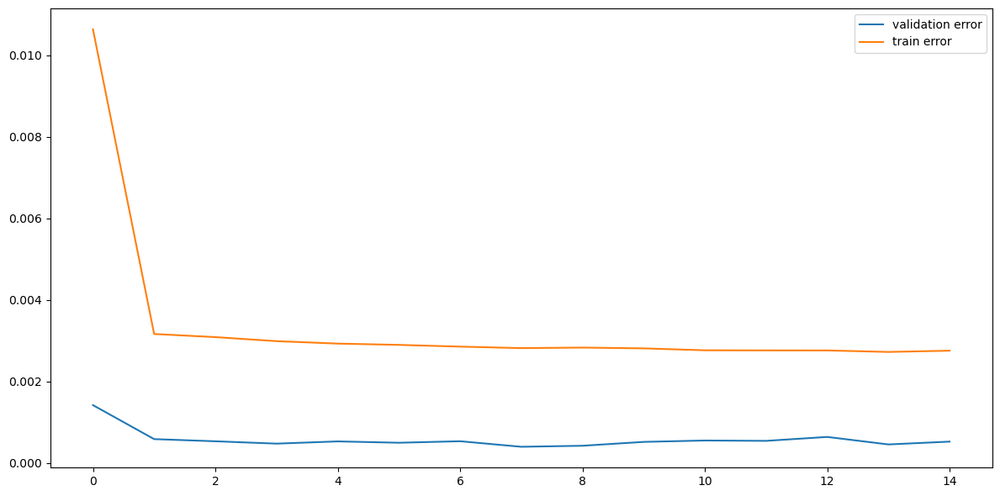

In [11]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-LOB-reg-LOSS.pdf')
plt.show()

In [12]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/LSTM1-LOB-best_model.pt', weights_only=False)

true = []
pred = []

torch.cuda.empty_cache()
# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-LOB-reg-pryce.html')
fig.show()

In [13]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-LOB-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-LOB-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

20.420925319194794
0.9941087923718043
0.018748181

21.764422953128815
0.9926390929247011
0.020974627

23.005099594593048
0.9913027580331888
0.022817923

25.733965635299683
0.987874669096306
0.0269849



### Astice

In [14]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [15]:
# Create the model
params = {
    "input_size": X_train.shape[1],
    "output_size": y_train.shape[1],
    "hidden_size": 64,
    "lstm_size": 64,
    "lstm_layers": 2,
    "smooth_conv_channels": 32
}

model = Models.Astice(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name,
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

model saved
model saved


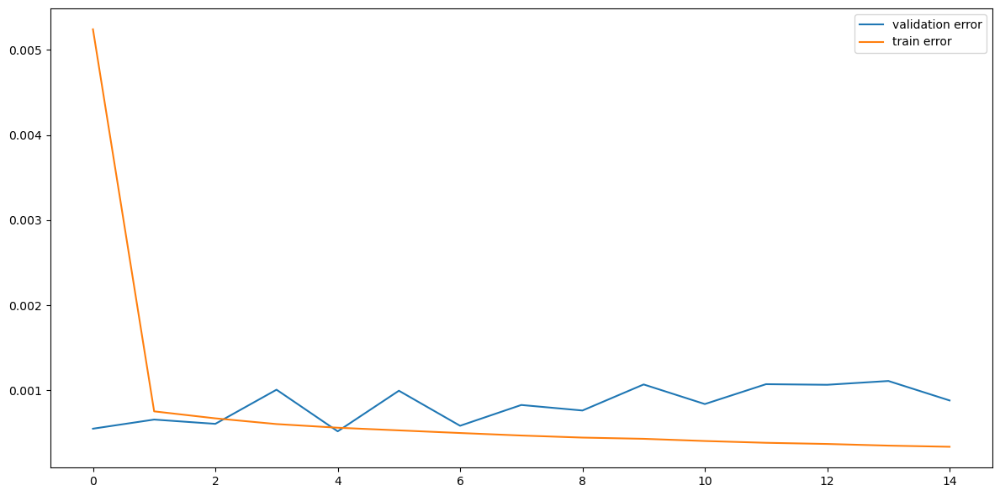

In [16]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-LOB-reg-LOSS.pdf')
plt.show()

In [17]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-LOB-best_model.pt', weights_only=False)

true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-LOB-reg-pryce.html')
fig.show()

In [18]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-LOB-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-LOB-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

18.832744657993317
0.99520320476458
0.01691736

18.834006786346436
0.9934487707155235
0.019787457

23.91687035560608
0.9910983390463496
0.02308452

27.821651101112366
0.9860940226020662
0.028898465



### LobCNN

In [19]:
dataset = pd.read_parquet('/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/Data/LOBSTER/MSFT.parquet')
dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
dataset = dataset.astype(float)
dataset = dataset.head(200000)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,309900.0,3788.0,309500.0,300.0,310500.0,100.0,309300.0,3986.0,310600.0,100.0,...,400.0,311300.0,100.0,308500.0,400.0,311400.0,100.0,308400.0,1600.0,309700.0
1,309900.0,3788.0,309500.0,300.0,310500.0,200.0,309300.0,3986.0,310600.0,100.0,...,400.0,311300.0,100.0,308500.0,400.0,311400.0,100.0,308400.0,1600.0,309700.0
2,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,200.0,...,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309700.0
3,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309700.0
4,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309700.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,308300.0,26720.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308200.0
199996,308300.0,28220.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308200.0
199997,308300.0,26720.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308200.0
199998,308300.0,25520.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308200.0


In [20]:
target_col = 'mid_price'
target_cols = []
shifts = [ 10, 20, 30, 50 ]

for shift in shifts:
    colname = f'Target_{shift}'
    target_cols.append(colname)
    dataset[colname] = dataset[target_col].shift(-shift)
dataset.dropna(inplace=True)

dataset = dataset.drop(['mid_price'], axis=1)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Target_10,Target_20,Target_30,Target_50
0,309900.0,3788.0,309500.0,300.0,310500.0,100.0,309300.0,3986.0,310600.0,100.0,...,308500.0,400.0,311400.0,100.0,308400.0,1600.0,309700.0,309700.0,309700.0,309600.0
1,309900.0,3788.0,309500.0,300.0,310500.0,200.0,309300.0,3986.0,310600.0,100.0,...,308500.0,400.0,311400.0,100.0,308400.0,1600.0,309700.0,309700.0,309700.0,309600.0
2,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,200.0,...,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309700.0,309700.0,309700.0,309600.0
3,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309700.0,309700.0,309700.0,309600.0
4,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309700.0,309700.0,309700.0,309600.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199945,308300.0,26220.0,308200.0,600.0,308400.0,24832.0,308100.0,13361.0,308500.0,15631.0,...,307400.0,3200.0,309200.0,7700.0,307300.0,1900.0,308250.0,308200.0,308200.0,308200.0
199946,308300.0,26220.0,308200.0,200.0,308400.0,24832.0,308100.0,13361.0,308500.0,15631.0,...,307400.0,3200.0,309200.0,7700.0,307300.0,1900.0,308250.0,308200.0,308200.0,308200.0
199947,308300.0,25520.0,308200.0,200.0,308400.0,24832.0,308100.0,13361.0,308500.0,15631.0,...,307400.0,3200.0,309200.0,7700.0,307300.0,1900.0,308250.0,308200.0,308200.0,308200.0
199948,308300.0,25520.0,308200.0,1400.0,308400.0,24832.0,308100.0,13361.0,308500.0,15631.0,...,307400.0,3200.0,309200.0,7700.0,307300.0,1900.0,308250.0,308200.0,308200.0,308200.0


In [21]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data
scaler = preprocessing.StandardScaler()
scaler.fit(dataset_train)
dataset_train[dataset_train.columns] = scaler.transform(dataset_train)
dataset_val[dataset_val.columns] = scaler.transform(dataset_val)
dataset_test[dataset_test.columns] = scaler.transform(dataset_test)

#means = dataset_train.mean(axis=0)
#stds = dataset_train.std(axis=0)
#
#means[-len(target_cols):] = means[target_cols]
#stds[-len(target_cols):] = stds[target_cols]
#
#dataset_train = ( dataset_train - means ) / stds
#dataset_val = ( dataset_val - means ) / stds
#dataset_test = ( dataset_test - means ) / stds

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Target_10,Target_20,Target_30,Target_50
0,0.843074,-0.781981,0.606118,-1.282494,1.292949,-1.551604,0.515686,-1.086627,1.292896,-1.582907,...,0.425168,-1.363993,1.382846,-0.712059,0.425168,-0.872068,0.725169,0.725231,0.725293,0.635094
1,0.843074,-0.781981,0.606118,-1.282494,1.292949,-1.538219,0.515686,-1.086627,1.292896,-1.582907,...,0.425168,-1.363993,1.382846,-0.712059,0.425168,-0.872068,0.725169,0.725231,0.725293,0.635094
2,0.843074,-0.781981,0.606118,-1.282494,1.202934,-1.551604,0.515686,-1.086627,1.202883,-1.569582,...,0.425168,-1.363993,1.292835,-0.712059,0.425168,-0.872068,0.725169,0.725231,0.725293,0.635094
3,0.843074,-0.781981,0.606118,-1.282494,1.202934,-1.551604,0.515686,-1.086627,1.202883,-1.556256,...,0.425168,-1.363993,1.292835,-0.712059,0.425168,-0.872068,0.725169,0.725231,0.725293,0.635094
4,0.843074,-0.781981,0.606118,-1.282494,1.202934,-1.551604,0.515686,-1.086627,1.202883,-1.556256,...,0.425168,-1.363993,1.292835,-0.712059,0.425168,-0.872068,0.725169,0.725231,0.725293,0.635094
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139960,0.032845,-0.385304,0.062803,1.571257,0.032737,1.152907,0.062889,1.171507,0.032714,0.530637,...,0.062923,1.654009,0.032688,-0.357233,0.062923,1.580890,0.047840,0.047890,0.047939,0.048034
139961,0.032845,-0.531571,0.062803,1.571257,0.032737,1.152907,0.062889,1.171507,0.032714,0.530637,...,0.062923,1.654009,0.032688,-0.357233,0.062923,1.580890,0.047840,0.047890,0.047939,0.048034
139962,0.032845,-0.531571,0.062803,1.571257,0.032737,1.152907,0.062889,1.171507,0.032714,0.530637,...,0.062923,1.654009,0.032688,-0.357233,0.062923,1.580890,0.047840,0.047890,0.047939,0.048034
139963,0.032845,-0.560825,0.062803,1.571257,0.032737,1.152907,0.062889,1.171507,0.032714,0.530637,...,0.062923,1.654009,0.032688,-0.357233,0.062923,1.580890,0.047840,0.047890,0.047939,0.048034


In [22]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, target_cols)
X_val, y_val = utils.DataTools.split_x_y(dataset_val, target_cols)
X_test, y_test = utils.DataTools.split_x_y(dataset_test, target_cols)

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = True,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = True,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = 1,
    offset    = lookback_period-1,
    channels  = True,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 139766 samples
Test dataset: 29794 samples


In [23]:
dataloader_train.dataset.channels = True
dataloader_val.dataset.channels = True
dataloader_test.dataset.channels = True

In [24]:
# Create the model

params = {
    "vertical_convolutional_layers" : 2,
    "vertical_kernel_size" : 4,
    "smoothing" : False,
    "convolution_channels" : 32,
    "inception_channels" : 64,
    "lstm_layers" : 2,
    "latent_size" : 128,
    "dropout" : 0.1,
    "output_size" : y_train.shape[1],
}

model = Models.LobCNN(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = model.name,
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

/home/joel/anaconda3/lib/python3.12/site-packages/torch/nn/modules/conv.py:454: UserWarning:

Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /opt/conda/conda-bld/pytorch_1720538455419/work/aten/src/ATen/native/Convolution.cpp:1031.)



model saved
model saved
model saved


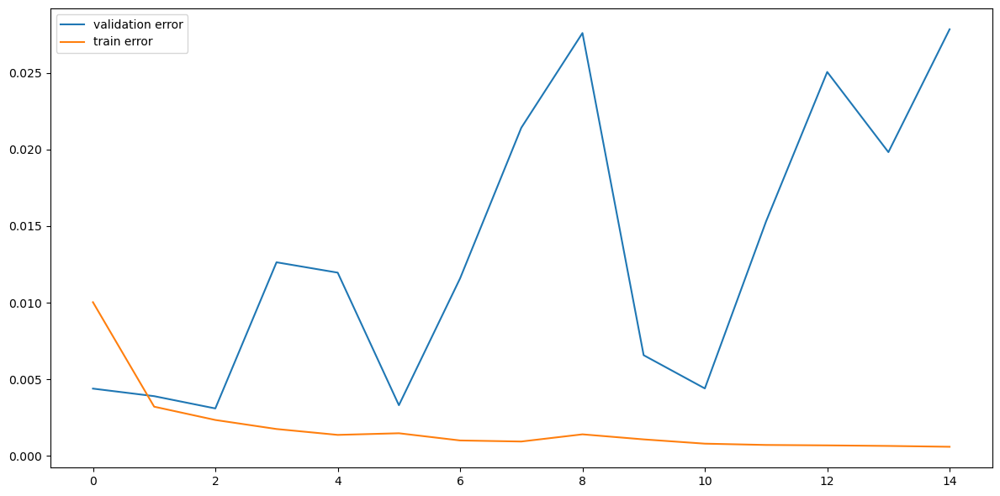

In [25]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-LOB-reg-LOSS.pdf')
plt.show()

In [26]:
# load the best model (or the final one)
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-LOB-best_model.pt', weights_only=False)

true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = best_model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true).reshape(-1, y_train.shape[1])
pred = np.concatenate(pred).reshape(-1, y_train.shape[1])

# Plot each dimension separately
fig = make_subplots(rows=y_train.shape[1], cols=1)
for i in range(y_train.shape[1]):
    fig.add_scatter(y=true[:,i], mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(y=pred[:,i], mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {[shifts[i] for i in range(y_train.shape[1])]}", xaxis_title = "Time", yaxis_title = "Price", height=1600)
fig.write_html(f'./figures/{best_model.name}-LOB-reg-pryce.html')
fig.show()

In [27]:
np.save(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-LOB-reg.npy', true, pred)
torch.save(model.state_dict(), f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/{model.name}-LOB-reg.pth')

for i in range(len(shifts)):
    print(utils.Metrics.sMAPE(true[:, i], pred[:, i]))
    print(r2_score(true[:, i], pred[:, i]))
    print(root_mean_squared_error(true[:, i], pred[:, i]))
    print()

55.15289902687073
0.9415046401546467
0.059076898

54.81498837471008
0.9423143825213515
0.058716796

54.850614070892334
0.9422833502757297
0.05878085

55.565786361694336
0.9366778589497959
0.061666857



### LSTM seq-to-seq with Attention

In [28]:
dataset = pd.read_parquet('/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/Data/LOBSTER/MSFT.parquet')
dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
dataset = dataset.astype(float)
dataset = dataset.head(200000)
display(dataset)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,309900.0,3788.0,309500.0,300.0,310500.0,100.0,309300.0,3986.0,310600.0,100.0,...,400.0,311300.0,100.0,308500.0,400.0,311400.0,100.0,308400.0,1600.0,309700.0
1,309900.0,3788.0,309500.0,300.0,310500.0,200.0,309300.0,3986.0,310600.0,100.0,...,400.0,311300.0,100.0,308500.0,400.0,311400.0,100.0,308400.0,1600.0,309700.0
2,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,200.0,...,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309700.0
3,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309700.0
4,309900.0,3788.0,309500.0,300.0,310400.0,100.0,309300.0,3986.0,310500.0,300.0,...,400.0,311100.0,4500.0,308500.0,400.0,311300.0,100.0,308400.0,1600.0,309700.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,308300.0,26720.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308200.0
199996,308300.0,28220.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308200.0
199997,308300.0,26720.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308200.0
199998,308300.0,25520.0,308100.0,13361.0,308400.0,25432.0,308000.0,19380.0,308500.0,15631.0,...,3200.0,309100.0,12300.0,307300.0,2500.0,309200.0,7700.0,307200.0,3415.0,308200.0


In [29]:
# Split the dataframe into train, validation and test
dataset_train, dataset_val, dataset_test = utils.DataTools.train_val_test_split(dataset)

# Standardize the data
scaler = preprocessing.StandardScaler()
scaler.fit(dataset_train)

dataset_train[dataset_train.columns] = scaler.fit_transform(dataset_train)
dataset_val[dataset_val.columns] = scaler.fit_transform(dataset_val)
dataset_test[dataset_test.columns] = scaler.fit_transform(dataset_test)

display(dataset_train)

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,mid_price
0,0.843171,-0.781946,0.606178,-1.282673,1.293103,-1.551829,0.515734,-1.086868,1.293049,-1.583171,...,-1.527201,1.383045,-0.768001,0.425205,-1.364119,1.383010,-0.712047,0.425205,-0.872302,0.725185
1,0.843171,-0.781946,0.606178,-1.282673,1.293103,-1.538444,0.515734,-1.086868,1.293049,-1.583171,...,-1.527201,1.383045,-0.768001,0.425205,-1.364119,1.383010,-0.712047,0.425205,-0.872302,0.725185
2,0.843171,-0.781946,0.606178,-1.282673,1.203076,-1.551829,0.515734,-1.086868,1.203025,-1.569844,...,-1.527201,1.202999,-0.272672,0.425205,-1.364119,1.292988,-0.712047,0.425205,-0.872302,0.725185
3,0.843171,-0.781946,0.606178,-1.282673,1.203076,-1.551829,0.515734,-1.086868,1.203025,-1.556517,...,-1.527201,1.202999,-0.272672,0.425205,-1.364119,1.292988,-0.712047,0.425205,-0.872302,0.725185
4,0.843171,-0.781946,0.606178,-1.282673,1.203076,-1.551829,0.515734,-1.086868,1.203025,-1.556517,...,-1.527201,1.202999,-0.272672,0.425205,-1.364119,1.292988,-0.712047,0.425205,-0.872302,0.725185
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139995,0.032841,-0.370602,0.062795,1.474018,0.032733,1.152571,0.062881,0.540874,0.032710,0.330694,...,1.746753,0.032697,-0.160098,0.062915,1.607548,0.032684,-0.357183,0.062915,1.534807,0.047785
139996,0.032841,-0.516883,0.062795,1.474018,0.032733,1.152571,0.062881,0.540874,0.032710,0.330694,...,1.746753,0.032697,-0.160098,0.062915,1.607548,0.032684,-0.357183,0.062915,1.534807,0.047785
139997,0.032841,-0.516883,0.062795,1.474018,0.032733,1.152571,0.062881,0.540874,0.032710,0.330694,...,1.600996,0.032697,-0.160098,0.062915,1.607548,0.032684,-0.357183,0.062915,1.534807,0.047785
139998,0.032841,-0.516883,0.062795,1.474018,0.032733,1.152571,0.062881,0.462072,0.032710,0.330694,...,1.600996,0.032697,-0.160098,0.062915,1.607548,0.032684,-0.357183,0.062915,1.534807,0.047785


In [30]:
# Split covariates and response variables
X_train, y_train = utils.DataTools.split_x_y(dataset_train, ['mid_price'])
X_val, y_val = utils.DataTools.split_x_y(dataset_val, ['mid_price'])
X_test, y_test = utils.DataTools.split_x_y(dataset_test, ['mid_price'])

# Convert to pytorch tensors
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, dtype=torch.float32 )

# Create Torch Dataset
lookback_period = 100
seq_len_y = 51
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = lookback_period,
    seq_len_y = seq_len_y,
    offset    = lookback_period,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = lookback_period,
    seq_len_y = seq_len_y,
    offset    = lookback_period,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = lookback_period,
    seq_len_y = seq_len_y,
    offset    = lookback_period,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.REGRESSION
)

# Create Torch DataLoader
batch_size = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = batch_size,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = batch_size,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 139800 samples
Test dataset: 29800 samples


In [31]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [32]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'output_size': y_train.shape[1],
    'encoder_hidden_size': 64,
    'decoder_hidden_size': 64,
    'num_layers': 2,
    'dropout': 0.2
}

model = Models.LSTMSeq2SeqAttention(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train_seq_to_seq(
    model_id = model.name,
    model = model,
    teacher_forcing_ratio = 0.5,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

model saved
model saved
model saved
model saved
model saved
model saved


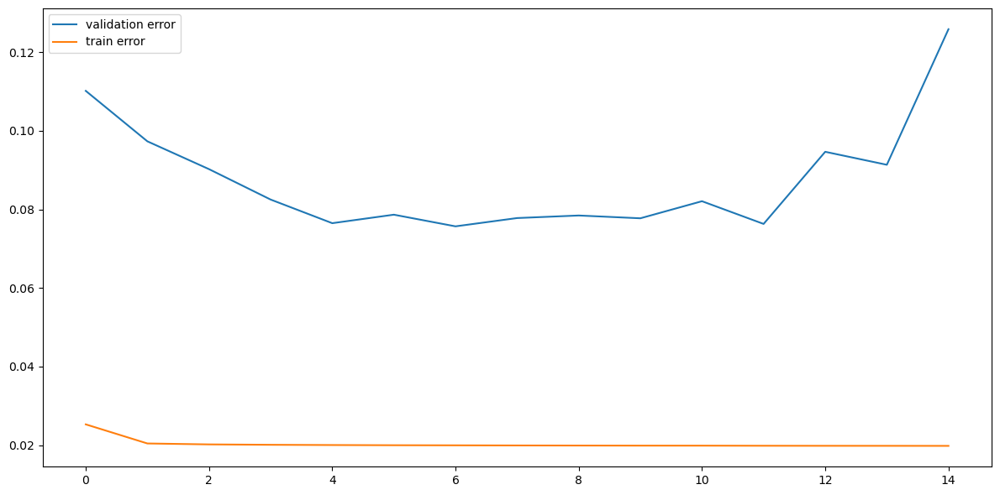

In [33]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-LOB-reg-LOSS.pdf')
plt.show()

In [34]:
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-LOB-best_model.pt', weights_only=False)

shifts = [ 1, 10, 20, 50 ]

fig = make_subplots(rows=len(shifts), cols=1)

# Evaluate the model
for i in range(len(shifts)):
    true = []
    pred = []
    with torch.no_grad():
        for inputs, labels in dataloader_test:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = best_model(inputs, labels, teacher_forcing_ratio=0.)
            true.append(labels[:,shifts[i],:].cpu().numpy())
            pred.append(outputs[:,shifts[i],:].cpu().numpy())
    
    true = np.concatenate(true)#.reshape(-1, y_train.shape[1])
    pred = np.concatenate(pred)#.reshape(-1, y_train.shape[1])
    
    fig.add_scatter(x=np.arange(len(true)), y=true.flatten(), mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(x=np.arange(len(pred)), y=pred.flatten(), mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {shifts}", xaxis_title = "Time", yaxis_title = "Price", height=1600)

fig.write_html(f'./figures/{best_model.name}-LOB-reg-pryce.html')
fig.show()

### lobCNN seq-to-seq with Attention

In [35]:
dataloader_train.dataset.channels = True
dataloader_val.dataset.channels = True
dataloader_test.dataset.channels = True

In [36]:
# Create the model
params = {
    'vertical_convolutional_layers' : 2,
    'vertical_kernel_size' : 4,
    'smoothing' : False,
    'convolution_channels' : 32,
    'inception_channels' : 64,
    'lstm_layers' : 2,
    'encoder_hidden_size' : 64,
    'decoder_hidden_size' : 64,
    'dropout' : 0.2,
    'output_size' : y_train.shape[1],
}

model = Models.LobCNN_seq2seq_Attention(**params).to(device)

# Define loss function and optimizer
learning_rate = 5*1e-4
epochs = 15
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train_seq_to_seq(
    model_id = model.name,
    model = model,
    teacher_forcing_ratio = 0.5,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = epochs,
    save = True,
    device = model.device
)

Training:   0%|          | 0/15 [00:00<?, ?it/s]

torch.Size([32, 100, 256])


RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

In [ ]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.savefig(f'./figures/{model.name}-LOB-reg-LOSS.pdf')
plt.show()

In [ ]:
best_model = torch.load(f'/home/joel/Desktop/DSSC/DEEP_LEARNING/stocks_forecasting_LOB/ModelsCheckpoints/regression/best_models/{model.name}-LOB-best_model.pt', weights_only=False)

shifts = [ 1, 10, 20, 49 ]

fig = make_subplots(rows=len(shifts), cols=1)

# Evaluate the model
for i in range(len(shifts)):
    true = []
    pred = []
    with torch.no_grad():
        for inputs, labels in dataloader_test:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = best_model(inputs, labels, teacher_forcing_ratio=0.)
            true.append(labels[:,shifts[i],:].cpu().numpy())
            pred.append(outputs[:,shifts[i],:].cpu().numpy())
    
    true = np.concatenate(true)#.reshape(-1, y_train.shape[1])
    pred = np.concatenate(pred)#.reshape(-1, y_train.shape[1])
    
    fig.add_scatter(x=np.arange(len(true)), y=true.flatten(), mode='lines', name= "Actual asset price", line_color = "navy", row=i+1, col=1)
    fig.add_scatter(x=np.arange(len(pred)), y=pred.flatten(), mode='lines', name= "Predicted asset price", line_color = "green", row=i+1, col=1)
    fig.update_layout(title = f"Horizons: {shifts}", xaxis_title = "Time", yaxis_title = "Price", height=1600)

fig.write_html(f'./figures/{best_model.name}-LOB-reg-pryce.html')
fig.show()